# 07 - Segmentação dos clientes por faixas de score
Faixas A-E definidas pela taxa real de inadimplência. Cortes escolhidos na validação (0,10 e 0,25 vêm da política), conferidos no teste fora do tempo e depois usados para caracterizar a submissão. Ver `src/segmentation.py`.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 200, 'display.max_columns', 50)


In [2]:
from src.train import *
from src.segmentation import *
from src.config import OUT
FIG = OUT / 'figures'; TAB = OUT / 'tables'; FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
m, cats, r, (X, y, tr, va, te, p) = rodar()
pv = m.predict_proba(X[va])[:, 1]
C = escolher_cortes(y[va], pv); print('cortes:', C)
tv, tt = tabela_faixas(y[va], pv, C), tabela_faixas(y[te], p, C)
print('VALIDAÇÃO'); print(tv.round(3).to_string()); print('TESTE (fora do tempo)'); print(tt.round(3).to_string())
print('faixas válidas no teste (taxa crescente, IC sem sobreposição, >=3%):', valido(tt))

cortes: [0.05, 0.1, 0.19, 0.25]
VALIDAÇÃO
       contratos  prob_media  inadimplencia  pct_carteira  ic95_inf  ic95_sup   lift             decisao
faixa                                                                                                   
A           4589       0.035          0.034         0.258     0.029     0.039  0.299             aprovar
B           6601       0.072          0.068         0.371     0.062     0.074  0.605             aprovar
C           3909       0.135          0.113         0.220     0.104     0.124  1.008  aprovar com ajuste
D            689       0.216          0.151         0.039     0.126     0.180  1.343  aprovar com ajuste
E           1992       0.438          0.426         0.112     0.404     0.448  3.788            rejeitar
TESTE (fora do tempo)
       contratos  prob_media  inadimplencia  pct_carteira  ic95_inf  ic95_sup   lift             decisao
faixa                                                                                           

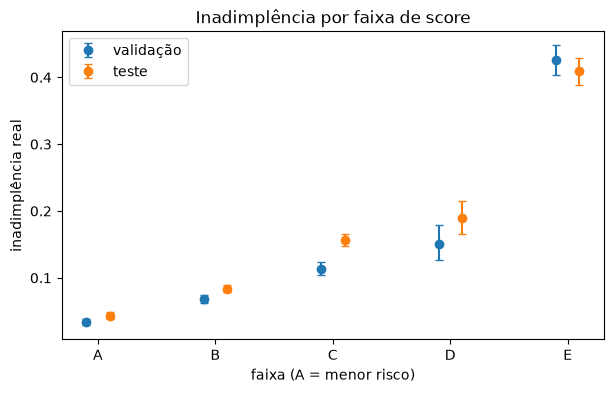

In [3]:
# taxa real por faixa: validação x teste, com IC95%
fig, ax = plt.subplots(figsize=(7, 4))
for t, nome, dx in ((tv, 'validação', -.1), (tt, 'teste', .1)):
    x = np.arange(5) + dx; ax.errorbar(x, t.inadimplencia, yerr=[t.inadimplencia - t.ic95_inf, t.ic95_sup - t.inadimplencia], fmt='o', capsize=3, label=nome)
ax.set_xticks(range(5)); ax.set_xticklabels(ROTULOS); ax.set_xlabel('faixa (A = menor risco)'); ax.set_ylabel('inadimplência real'); ax.legend(); ax.set_title('Inadimplência por faixa de score')
plt.savefig(FIG / 'segment_default_rate.png', dpi=130, bbox_inches='tight'); plt.show()

In [4]:
# submissão: faixa de cada cliente (modelo final) e conferência com a decisão do CSV
sub = pd.read_csv('../submissao/submission_predictions.csv').set_index('id_cliente')
sub['faixa'] = faixa(sub.prob_inadimplencia.values, C)
map_dec = {'A': 'aprovar', 'B': 'aprovar', 'C': 'aprovar com ajuste', 'D': 'aprovar com ajuste', 'E': 'rejeitar'}
assert (sub.faixa.map(map_dec) == sub.decisao).all()
cmp = pd.DataFrame({'submissão': sub.faixa.value_counts(normalize=True), 'teste': tt.pct_carteira, 'validação': tv.pct_carteira}).loc[ROTULOS]
print(len(sub), 'clientes'); print(cmp.round(3).to_string())
print('Atenção: a submissão tem mais clientes nas faixas de risco que o teste (ver README, deslocamento do histórico). A taxa real de cada faixa vem do teste, não da submissão.')

50000 clientes
       submissão  teste  validação
faixa                             
A          0.332  0.268      0.258
B          0.332  0.372      0.371
C          0.120  0.234      0.220
D          0.027  0.038      0.039
E          0.189  0.088      0.112
Atenção: a submissão tem mais clientes nas faixas de risco que o teste (ver README, deslocamento do histórico). A taxa real de cada faixa vem do teste, não da submissão.


In [5]:
# perfil: medianas das variáveis numéricas e proporções das categóricas por faixa
S = pd.read_parquet('../data/interim/submission.parquet').loc[sub.index].assign(faixa=sub.faixa)
num = [c for c in S.select_dtypes('number').columns]
med = S.groupby('faixa')[num].median().loc[ROTULOS].T; med['todos'] = S[num].median()
print(med.round(2).to_string())
cat = [c for c in S.select_dtypes(exclude='number').columns if c != 'faixa']
for c in cat: print(pd.crosstab(S[c].fillna('na'), S.faixa, normalize='columns').round(3)[ROTULOS].to_string(), '\n')

faixa                               A          B         C          D          E      todos
hora                            12.00      12.00     12.00      13.00      14.00      12.00
h_n_contratos                    6.00       3.00      2.00       3.00       2.00       3.00
h_dias_ult_decisao             238.00     336.00    485.00     479.00     701.00     345.00
h_n_recusado                     0.00       0.00      0.00       0.00       0.00       0.00
h_pct_recusado                   0.00       0.00      0.00       0.00       0.00       0.00
h_credito_medio             148251.38  103491.00  82894.50  132982.88  121861.07  119677.50
h_prazo_medio                   13.50      12.00     12.00      20.00      24.00      13.00
h_n_parcelas                    45.00      16.00      9.00      24.00      24.00      24.00
h_dpd_medio                      0.59       0.00      0.00       4.13       4.17       0.61
h_dpd_max                       15.00       0.00      0.00      65.00      35.00

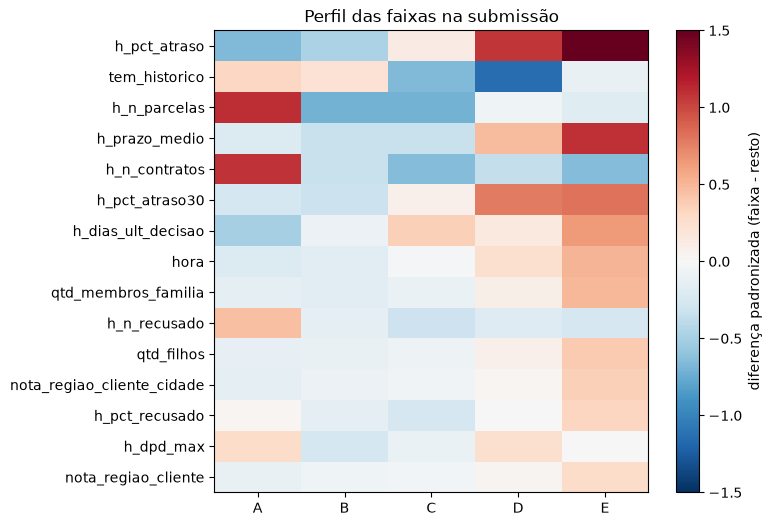

                               A     B     C     D     E
h_pct_atraso               -0.66 -0.48  0.12  1.07  1.71
tem_historico               0.31  0.21 -0.66 -1.14 -0.11
h_n_parcelas                1.11 -0.71 -0.71 -0.06 -0.18
h_prazo_medio              -0.21 -0.33 -0.34  0.47  1.10
h_n_contratos               1.08 -0.34 -0.66 -0.36 -0.66
h_pct_atraso30             -0.26 -0.32  0.08  0.78  0.82
h_dias_ult_decisao         -0.50 -0.09  0.36  0.15  0.64
hora                       -0.20 -0.17 -0.02  0.24  0.51
qtd_membros_familia        -0.14 -0.17 -0.10  0.08  0.50
h_n_recusado                0.46 -0.14 -0.31 -0.19 -0.25
qtd_filhos                 -0.13 -0.11 -0.08  0.08  0.39
nota_regiao_cliente_cidade -0.14 -0.09 -0.05  0.03  0.36
h_pct_recusado              0.03 -0.14 -0.25  0.00  0.32
h_dpd_max                   0.28 -0.26 -0.10  0.24  0.01
nota_regiao_cliente        -0.11 -0.06 -0.05  0.04  0.27


In [6]:
# o que distingue cada faixa: diferença padronizada da média contra o resto, e heatmap
z = pd.DataFrame({f: (S.loc[S.faixa == f, num].mean() - S.loc[S.faixa != f, num].mean()) / S[num].std() for f in ROTULOS})
z = z.loc[z.abs().max(axis=1).sort_values(ascending=False).index[:15]]
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(z, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
ax.set_xticks(range(5)); ax.set_xticklabels(ROTULOS); ax.set_yticks(range(len(z))); ax.set_yticklabels(z.index); plt.colorbar(im, label='diferença padronizada (faixa - resto)')
ax.set_title('Perfil das faixas na submissão'); plt.savefig(FIG / 'segment_profile.png', dpi=130, bbox_inches='tight'); plt.show()
print(z.round(2).to_string())

In [7]:
# SHAP médio por faixa: variáveis que mais empurram o score para cima em cada faixa
import joblib, shap
from src.config import MODELS
art = joblib.load(MODELS / 'lgbm.joblib')
Am = aplicar_cat(S.drop(columns='faixa'), art['cats'])[art['cols']]
idx = S.groupby('faixa', group_keys=False).apply(lambda g: g.sample(min(len(g), 800), random_state=42)).index
sv = shap.TreeExplainer(art['model']).shap_values(Am.loc[idx]); sv = sv[1] if isinstance(sv, list) else sv
sv = pd.DataFrame(sv, index=idx, columns=Am.columns).groupby(S.loc[idx, 'faixa']).mean().loc[ROTULOS]
for f in ROTULOS: print(f, '| sobe:', sv.loc[f].nlargest(3).round(2).to_dict(), '| desce:', sv.loc[f].nsmallest(3).round(2).to_dict())

A | sobe: {'prazo_implicito': 0.12, 'h_dias_ult_decisao': 0.02, 'qtd_filhos': 0.0} | desce: {'h_pct_atraso': -0.47, 'h_n_parcelas': -0.37, 'h_n_contratos': -0.18}
B | sobe: {'prazo_implicito': 0.11, 'h_dias_ult_decisao': 0.03, 'nota_regiao_cliente': 0.0} | desce: {'h_pct_atraso': -0.28, 'h_razao_paga': -0.16, 'h_prazo_medio': -0.08}
C | sobe: {'prazo_implicito': 0.19, 'h_n_parcelas': 0.16, 'h_dias_ult_decisao': 0.04} | desce: {'h_razao_paga': -0.1, 'h_prazo_medio': -0.05, 'credito_sobre_bem': -0.03}
D | sobe: {'h_pct_atraso': 0.33, 'prazo_implicito': 0.26, 'h_razao_paga': 0.12} | desce: {'h_n_contratos': -0.07, 'h_dpd_max': -0.06, 'nota_regiao_cliente_cidade': -0.0}
E | sobe: {'h_pct_atraso': 0.55, 'prazo_implicito': 0.31, 'h_razao_paga': 0.27} | desce: {'h_dpd_max': -0.02, 'h_n_parcelas': -0.01, 'hora': -0.0}


In [8]:
# tabela final do perfil
perf = tt[['contratos', 'pct_carteira', 'prob_media', 'inadimplencia', 'ic95_inf', 'ic95_sup', 'decisao']].add_prefix('teste_')
perf['submissao_pct'] = cmp['submissão']
perf = perf.join(S.groupby('faixa')[num].median().add_suffix('_mediana')).join(sv.add_prefix('shap_'))
perf.round(4).to_csv(TAB / 'segment_profile.csv'); print(perf.shape, '-> outputs/tables/segment_profile.csv')

(5, 65) -> outputs/tables/segment_profile.csv
